# Traveling-wave analysis of macaque motor-cortex recordings

This notebook detects and characterizes traveling-wave episodes in local field potential (LFP) recordings from macaque motor cortex. It loads electrophysiological and behavioral data, extracts trial-aligned windows, and selects an oscillatory frequency band from the mean Welch power spectrum or a manually specified range. Data paths and analysis parameters are specified in the configuration cell.

## Data setup

Download this repository and the experimental data from Zenodo. Create a folder named Macaque_data alongside this notebook and place both input files inside it:

Beh_matrix.mat

rs1050225_MI_clean_LFP.mat

Run Jupyter from the directory containing the notebook. If you store the data elsewhere, update DATA_DIR in the configuration cell to point to that folder.

### Signal preprocessing

LFP channels are z-scored using the mean and standard deviation within each analysis window. Missing electrode sites are reconstructed by spatial interpolation of the LFP signals. Channels are band-pass filtered using a fourth-order Butterworth filter applied forward and backward, with surrounding temporal context to reduce edge effects.

Instantaneous phases are extracted using the Hilbert transform, spatially unwrapped along the two grid dimensions, and referenced to the central electrode. Temporal phase derivatives are computed before spatial referencing.

### Wave detection using a fixed spatial resultant threshold

At each time point, local spatial phase gradients are normalized to unit vectors:

$$
\mathbf{u}(x,y,t)=
\frac{\nabla\phi(x,y,t)}{\|\nabla\phi(x,y,t)\|}.
$$

Their spatial alignment is quantified by the directional resultant:

$$
r(t)=
\left\|\left\langle\mathbf{u}(x,y,t)\right\rangle_{x,y}\right\|.
$$

The average includes only gradients exceeding the configured minimum magnitude. The resultant ranges from 0 to 1: larger values indicate stronger alignment of local gradient directions. Each valid location contributes equally, regardless of its gradient magnitude.

Wave epochs are contiguous intervals during which $r(t)$ exceeds the configured threshold, lasting at least the configured minimum duration. With the default settings, these criteria are $r>0.4$ and a duration of at least $10\,\mathrm{ms}$. Plane-fit residuals are computed as diagnostics but are not used to select epochs.

### Propagation direction

A plane is fitted to each instantaneous phase map:

$$
\hat{\phi}(x,y,t)=a(t)x+b(t)y+c(t).
$$

The temporal phase slope $\omega(t)$ is calculated as the median across electrodes of the temporal derivative of the temporally unwrapped phase. The propagation unit vector is then

$$
\mathbf{d}(t)=
-\operatorname{sgn}[\omega(t)]
\frac{(a(t),b(t))}{\sqrt{a(t)^2+b(t)^2}}.
$$

Frames with undefined temporal slopes, zero temporal slopes, or near-zero fitted gradients are excluded from the direction estimate. Valid unit vectors are averaged within each epoch, and the angle of the resulting vector gives one propagation direction per epoch.

The main direction histogram weights each epoch equally. The optional frame-level histogram instead includes every valid accepted frame, giving longer epochs more weight. Angles use the array coordinates: $x$ follows columns and $y$ follows rows. Anatomical interpretation requires a verified mapping between these coordinates and the cortical axes.

### Speed and wavelength

Instantaneous propagation speed is estimated as

$$
v(t)=
\frac{|\omega(t)|}
{\left\langle\|\nabla\phi(x,y,t)\|\right\rangle_{x,y}}.
$$

Gradients are expressed in rad/mm and temporal slopes in rad/s; speeds are converted from mm/s to cm/s. The notebook stores both individual accepted-frame speeds and the mean speed of each epoch.

In this notebook, the wavelength of each epoch is calculated from the magnitude of the local gradient vector averaged across space and time:

$$
\lambda_{\mathrm{wave}}=
\frac{2\pi}
{\left\|\left\langle\nabla\phi(x,y,t)\right\rangle_{x,y,t\in\mathrm{wave}}\right\|}.
$$

Wavelengths are converted to centimetres. This estimator differs from averaging the instantaneous magnitudes of the plane-fit slopes; changes in gradient direction within an epoch can reduce the mean vector magnitude and increase the estimated wavelength.

### Outputs

The analysis exports trial-level diagnostics and event-level measurements to a MATLAB-compatible `.mat` file and generates summary plots. Saved results include propagation directions, wavelengths, accepted-frame speeds, event-mean speeds, and analysis settings.

The fixed-$r$ criterion measures spatial coherence; it is not a statistical significance test. Changing the threshold or minimum duration can change epoch boundaries and consequently the distributions of estimated wave properties.

Find the exported .mat results in the folder "results".

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import loadmat, savemat
from scipy.interpolate import LinearNDInterpolator
from scipy.spatial import cKDTree

DATA_DIR = Path("Macaque_data")
OUTPUT_DIR = Path("results")
LFP_FILENAME = "rs1050225_MI_clean_LFP.mat"
BEHAVIOR_FILENAME = "Beh_matrix.mat"
NUMBER_TRIALS = 300

MANUAL_BAND_HZ = None #(10.0, 45.0)  
PRE_ONSET_MS = 0
DURATION_MS = 800

GRID_SIDE = 10
ELECTRODE_SPACING_MM = 0.4
EXCLUDED_CHANNELS_MATLAB = [2, 25, 66, 67, 74]  # 1-based lfp-variable indices
CHANNEL_NAMES = None  # Optional explicit ordered list matching MIchan2rc rows.
LFP_SAMPLE_INTERVAL_MS = 1.0
FILTER_ORDER = 4
FILTER_CONTEXT_MS = 1000
BAND_SEARCH_HZ = (11.0, 30.0)
BAND_HALF_WIDTH_HZ = 3.0
 

FIXED_R_THRESHOLD = 0.4

MIN_WAVE_DURATION_MS = 10.0
MIN_GRADIENT_MM_INV = 1e-3
N_DIRECTION_BINS = 24
BAND_SEARCH_HZ = (10.0, 50.0)
BAND_LIMITS_HZ = (10.0, 30.0)
BAND_HALF_WIDTH_HZ = 3.0
 

In [2]:
def load_inputs():    
    missing = [
    name for name in (LFP_FILENAME, BEHAVIOR_FILENAME)
    if not (DATA_DIR / name).is_file()
    ]
    if missing:
        raise FileNotFoundError(
            f"Missing files: {', '.join(missing)}\n"
            f"Expected folder: {DATA_DIR.resolve()}\n"
            "Download the experimental data from "
            "https://doi.org/10.5281/zenodo.19420479 "
            "and place both MAT files in this folder, "
            "or update DATA_DIR in the configuration cell."
        )
    try:
        mat = loadmat(DATA_DIR / LFP_FILENAME)
        behavior = loadmat(DATA_DIR / BEHAVIOR_FILENAME)
    except NotImplementedError as exc:
        raise ValueError("These files use MATLAB v7.3/HDF5; this notebook needs standard MAT files.") from exc
    names = list(CHANNEL_NAMES) if CHANNEL_NAMES is not None else [k for k in mat if k.startswith("lfp")]
    if not names or "MIchan2rc" not in mat or "beh" not in behavior:
        raise ValueError("Expected lfp* variables, MIchan2rc, and beh.")
    coords = np.asarray(mat["MIchan2rc"], dtype=float)
    if coords.ndim != 2 or coords.shape[1] != 2 or len(coords) < len(names):
        raise ValueError("MIchan2rc must contain one [row, column] per LFP channel.")
    coords = coords[:len(names)]
    if not np.all(np.isfinite(coords)) or not np.all(coords == np.round(coords)):
        raise ValueError("Grid coordinates must be finite integer indices.")
    coords = coords.astype(int) - 1
    if np.any(coords < 0) or np.any(coords >= GRID_SIDE) or len(np.unique(coords, axis=0)) != len(coords):
        raise ValueError("Invalid or duplicate grid positions.")
    excluded = np.asarray(EXCLUDED_CHANNELS_MATLAB, dtype=int) - 1
    if np.any(excluded < 0) or np.any(excluded >= len(names)):
        raise ValueError("An excluded channel index is outside the available LFP channels.")
    keep = [i for i in range(len(names)) if i not in set(excluded)]
    vectors = [np.asarray(mat[names[i]], dtype=float).reshape(-1) for i in keep]
    if len({len(v) for v in vectors}) != 1:
        raise ValueError("LFP channel lengths differ.")
    data = np.column_stack(vectors)
    if not np.all(np.isfinite(data)):
        raise ValueError("Retained LFP channels contain NaN/Inf; inspect channel exclusion.")
    beh = np.asarray(behavior["beh"], dtype=float)
    if beh.ndim != 2 or beh.shape[1] < 1 or not 2 <= NUMBER_TRIALS <= len(beh):
        raise ValueError("NUMBER_TRIALS must be between 2 and the number of behavioral rows.")
    if int(NUMBER_TRIALS) != NUMBER_TRIALS:
        raise ValueError("NUMBER_TRIALS must be an integer.")
    print(f"Loaded {data.shape[0]} samples, {data.shape[1]} retained channels.")
    print("Verify this variable order against MIchan2rc:", names)
    return data, coords[keep], beh, [names[i] for i in keep]


def trial_windows(beh, n_samples):
    fs = 1000.0 / LFP_SAMPLE_INTERVAL_MS
    n_duration = DURATION_MS / LFP_SAMPLE_INTERVAL_MS
    n_pre = PRE_ONSET_MS / LFP_SAMPLE_INTERVAL_MS
    if n_duration != round(n_duration) or n_pre != round(n_pre):
        raise ValueError("Trial duration and offset must align with sample times.")
    windows = []
    for trial in range(NUMBER_TRIALS):
        onset = beh[trial, 0]
        if not np.isfinite(onset):
            raise ValueError(f"Trial {trial+1}: nonfinite onset.")
        # Match MATLAB's max(1, floor(onset*fs)-200), then convert to 0-based.
        start = max(1, int(np.floor(onset*fs)) - int(n_pre)) - 1
        stop = start + int(n_duration)
        if not 0 <= start < stop <= n_samples:
            raise ValueError(f"Trial {trial+1}: complete requested window unavailable.")
        windows.append((start, stop))
    return windows




def zscore_channels(values, reference):
    """Normalize using the mean and SD of the analysis window."""
    mean = reference.mean(axis=0, keepdims=True)
    std = reference.std(axis=0, keepdims=True)

    if np.any(~np.isfinite(std)) or np.any(std == 0):
        raise ValueError("A channel has invalid or zero SD in this trial.")

    return (values - mean) / std
    
def choose_band(data, windows):
    fs = 1000.0 / LFP_SAMPLE_INTERVAL_MS
    nperseg = min(1000, min(b-a for a,b in windows))
    if nperseg < 4:
        raise ValueError("Trial windows too short for PSD.")
    mean_psd = None
    for start, stop in windows:
        segment = data[start:stop]
        segment = zscore_channels(segment, segment)
        
        freq, psd = signal.welch(
            segment,
            fs=fs,
            nperseg=nperseg,
            noverlap=nperseg // 2,
            nfft=max(2048, nperseg),
            axis=0,
        )
        p = psd.mean(axis=1)
        mean_psd = p if mean_psd is None else mean_psd + p
    mean_psd /= len(windows)
    use = (freq >= BAND_SEARCH_HZ[0]) & (freq <= BAND_SEARCH_HZ[1])
    if not np.any(use):
        raise ValueError("No PSD bins in BAND_SEARCH_HZ.")
    peak = float(freq[use][np.argmax(mean_psd[use])])


    band = tuple(MANUAL_BAND_HZ) if MANUAL_BAND_HZ is not None else (
    max(BAND_LIMITS_HZ[0], peak - BAND_HALF_WIDTH_HZ),
    min(BAND_LIMITS_HZ[1], peak + BAND_HALF_WIDTH_HZ))
    
    if not 0 < band[0] < band[1] < fs/2:
        raise ValueError(f"Invalid band {band}.")
    return peak, band, freq, mean_psd


def interpolation_weights(coords):
    # Grid in row-major order, consistent with reshape(time, rows, columns).
    yy, xx = np.mgrid[:GRID_SIDE, :GRID_SIDE]
    target = np.column_stack((yy.ravel(),xx.ravel()))
    weights = np.asarray(LinearNDInterpolator(coords, np.eye(len(coords)))(target))
    missing = ~np.all(np.isfinite(weights),axis=1)
    nearest = cKDTree(coords).query(target[missing])[1]
    weights[missing] = np.eye(len(coords))[nearest]
    # Preserve measured sites exactly.
    weights[coords[:,0]*GRID_SIDE+coords[:,1]] = np.eye(len(coords))
    return weights


In [3]:
def plane_design(n_side):
    x_mm, y_mm = np.meshgrid(
        np.arange(n_side) * ELECTRODE_SPACING_MM,
        np.arange(n_side) * ELECTRODE_SPACING_MM,
    )
    design = np.column_stack((x_mm.ravel(), y_mm.ravel(), np.ones(n_side**2)))
    return design, np.linalg.pinv(design)

def phase_metrics(phases, design, pinv_design):
    """Spatial unit-gradient resultant r, residual, and plane-fit slopes."""
    grad_y, grad_x = np.gradient(
        phases,
        ELECTRODE_SPACING_MM,
        ELECTRODE_SPACING_MM,
        axis=(1, 2),
        edge_order=1,
    )
    grad_norm = np.hypot(grad_x, grad_y)
    valid = grad_norm > MIN_GRADIENT_MM_INV
    n_valid = valid.sum(axis=(1, 2)).astype(float)

    unit_x = np.divide(grad_x, grad_norm, out=np.zeros_like(grad_x), where=valid)
    unit_y = np.divide(grad_y, grad_norm, out=np.zeros_like(grad_y), where=valid)
    mean_x = np.divide(
        unit_x.sum(axis=(1, 2)),
        n_valid,
        out=np.zeros_like(n_valid),
        where=n_valid > 0,
    )
    mean_y = np.divide(
        unit_y.sum(axis=(1, 2)),
        n_valid,
        out=np.zeros_like(n_valid),
        where=n_valid > 0,
    )
    spatial_r = np.clip(np.hypot(mean_x, mean_y), 0.0, 1.0)

    phase_flat = phases.reshape(phases.shape[0], -1)
    coefficients = phase_flat @ pinv_design.T
    fitted = coefficients @ design.T
    residual = np.sqrt(np.mean((phase_flat - fitted) ** 2, axis=1))
    return spatial_r, residual, grad_x, grad_y, coefficients[:, 0], coefficients[:, 1]


def event_directions(r, kx, ky, omega, speed, eligible, r_cut, simulation_id):
    detected = (r > r_cut) & eligible
    changes = np.flatnonzero(np.diff(np.r_[False, detected, False].astype(int)))
    minimum = max(1, int(np.ceil(MIN_WAVE_DURATION_MS/LFP_SAMPLE_INTERVAL_MS)))
    records = []
    for start, stop in zip(changes[::2], changes[1::2]):
        if stop-start < minimum:
            continue
        a, b, w = kx[start:stop], ky[start:stop], omega[start:stop]
        k = np.hypot(a, b)
        valid = np.isfinite(k) & (k > MIN_GRADIENT_MM_INV) & np.isfinite(w) & (w != 0)
        angle = resultant = np.nan
        if valid.any():
            ux = -np.sign(w[valid])*a[valid]/k[valid]
            uy = -np.sign(w[valid])*b[valid]/k[valid]
            resultant = float(np.hypot(ux.mean(), uy.mean()))
            if resultant > np.finfo(float).eps:
                angle = float(np.arctan2(uy.mean(), ux.mean()) % (2*np.pi))
        event_speed = speed[start:stop]
        good_speed = np.isfinite(event_speed)
        mean_speed = float(event_speed[good_speed].mean()) if good_speed.any() else np.nan
        records.append(dict(simulation_id=simulation_id, start_frame=int(start),
            stop_frame_exclusive=int(stop), start_ms=start*LFP_SAMPLE_INTERVAL_MS,
            stop_ms_exclusive=stop*LFP_SAMPLE_INTERVAL_MS,
            mean_speed_cm_s=mean_speed, valid_speed_fraction=float(good_speed.mean()),
            duration_ms=(stop-start)*LFP_SAMPLE_INTERVAL_MS,
            direction_rad=angle, direction_deg=np.degrees(angle),
            direction_resultant=resultant, valid_direction_fraction=float(valid.mean())))
    return records




In [4]:
def analyse_recordings(data, coords, windows, band):
    if not np.isfinite(FIXED_R_THRESHOLD) or not 0 <= FIXED_R_THRESHOLD < 1:
        raise ValueError("Require 0 <= FIXED_R_THRESHOLD < 1.")
    if MIN_WAVE_DURATION_MS <= 0 or FILTER_CONTEXT_MS < 0:
        raise ValueError("Invalid duration or filter context.")
    fs = 1000.0/LFP_SAMPLE_INTERVAL_MS
    sos = signal.butter(FILTER_ORDER,band,btype="bandpass",fs=fs,output="sos")
    weights = interpolation_weights(coords)
    design, pinv = plane_design(GRID_SIDE)
    context = int(np.ceil(FILTER_CONTEXT_MS/LFP_SAMPLE_INTERVAL_MS))
    events, trials, speed_chunks, speed_trial_chunks, speed_time_chunks = [], [], [], [], []
    for trial_id,(start,stop) in enumerate(windows,1):
        lo, hi = max(0,start-context), min(len(data),stop+context)
        # Normalize using the analysed trial, including when filtering extra context.
        normalized = zscore_channels(data[lo:hi], data[start:stop])
        grid_lfp = normalized @ weights.T
        filtered = signal.sosfiltfilt(sos,grid_lfp,axis=0)
        raw = np.angle(signal.hilbert(filtered,axis=0))
        omega_full = np.median(np.gradient(np.unwrap(raw,axis=0),1/fs,axis=0),axis=1)
        selection = slice(start-lo,stop-lo)
        omega = omega_full[selection]
        phases = raw[selection].reshape(stop-start,GRID_SIDE,GRID_SIDE)
        phases = np.unwrap(np.unwrap(phases,axis=1),axis=2)
        phases -= phases[:,GRID_SIDE//2,GRID_SIDE//2][:,None,None]
        r,residual,gx,gy,kx,ky = phase_metrics(phases,design,pinv)
        mean_norm = np.hypot(gx,gy).mean(axis=(1,2))
        speed = np.full(stop-start,np.nan)
        ok = np.isfinite(omega) & np.isfinite(mean_norm) & (mean_norm > MIN_GRADIENT_MM_INV)
        speed[ok] = np.abs(omega[ok])/mean_norm[ok]/10.0
        records = event_directions(r,kx,ky,omega,speed,np.ones(len(r),bool),
            FIXED_R_THRESHOLD,trial_id)
        accepted = np.zeros(len(r),bool)
        for record in records:
            record["trial_id"] = record.pop("simulation_id")
            a,b = record["start_frame"],record["stop_frame_exclusive"]
            accepted[a:b] = True
            # Preserve legacy event-mean-gradient wavelength, expressed in cm.
            g = np.hypot(gx[a:b].mean(),gy[a:b].mean())
            record["wavelength_cm"] = 2*np.pi/g/10.0 if g > MIN_GRADIENT_MM_INV else np.nan
            record["recording_start_sample"] = start+a
            record["recording_stop_sample_exclusive"] = start+b
        selected = np.flatnonzero(accepted & np.isfinite(speed))
        speed_chunks.append(speed[selected])
        speed_trial_chunks.append(np.full(len(selected),trial_id,dtype=int))
        speed_time_chunks.append(selected*LFP_SAMPLE_INTERVAL_MS)
        events.extend(records)
        trials.append(dict(trial_id=trial_id,recording_start_sample=start,
            recording_stop_sample_exclusive=stop,R=r,e_resid=residual,speed=speed,
            omega=omega,kx=kx,ky=ky,accepted=accepted,
            LFP=filtered[selection].reshape(stop-start,GRID_SIDE,GRID_SIDE).transpose(1,2,0),
            Ph=phases.transpose(1,2,0)))
        print(f"Trial {trial_id}: {len(records)} events, {len(selected)} finite frame speeds")
    return events,trials,dict(all_speeds=np.concatenate(speed_chunks),
        speed_trial_ids=np.concatenate(speed_trial_chunks),
        speed_times_ms=np.concatenate(speed_time_chunks))


In [5]:
data, coords, beh, retained_channel_names = load_inputs()
windows = trial_windows(beh,len(data))
peak_hz, band_hz, frequencies, mean_psd = choose_band(data,windows)
print(f"PSD peak {peak_hz:.3f} Hz; filtering {band_hz} Hz")
events, trial_results, speed_results = analyse_recordings(data,coords,windows,band_hz)
print(f"Total: {len(events)} events across {len(windows)} trials")


Loaded 2769460 samples, 91 retained channels.
Verify this variable order against MIchan2rc: ['lfp1', 'lfp2', 'lfp3', 'lfp4', 'lfp5', 'lfp6', 'lfp7', 'lfp8', 'lfp9', 'lfp10', 'lfp11', 'lfp12', 'lfp13', 'lfp14', 'lfp15', 'lfp16', 'lfp17', 'lfp18', 'lfp19', 'lfp20', 'lfp21', 'lfp22', 'lfp23', 'lfp24', 'lfp25', 'lfp26', 'lfp27', 'lfp28', 'lfp29', 'lfp30', 'lfp31', 'lfp32', 'lfp33', 'lfp34', 'lfp35', 'lfp36', 'lfp37', 'lfp38', 'lfp39', 'lfp40', 'lfp41', 'lfp42', 'lfp43', 'lfp44', 'lfp45', 'lfp46', 'lfp47', 'lfp48', 'lfp49', 'lfp50', 'lfp51', 'lfp52', 'lfp53', 'lfp54', 'lfp55', 'lfp56', 'lfp57', 'lfp58', 'lfp59', 'lfp60', 'lfp61', 'lfp62', 'lfp63', 'lfp64', 'lfp65', 'lfp66', 'lfp67', 'lfp68', 'lfp69', 'lfp70', 'lfp71', 'lfp72', 'lfp73', 'lfp74', 'lfp75', 'lfp76', 'lfp77', 'lfp78', 'lfp79', 'lfp80', 'lfp81', 'lfp82', 'lfp83', 'lfp84', 'lfp85', 'lfp86', 'lfp87', 'lfp88', 'lfp89', 'lfp90', 'lfp91', 'lfp92', 'lfp93', 'lfp94', 'lfp95', 'lfp96']
PSD peak 16.602 Hz; filtering (10.0, 45.0) Hz
Trial 

In [6]:
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
filename = (f"Macaque_R_trials_{NUMBER_TRIALS}_DWfilter_{BAND_HALF_WIDTH_HZ:g}"
            f"_r{FIXED_R_THRESHOLD:.2f}.mat")
output_path = OUTPUT_DIR/filename
settings = dict(threshold_method="fixed_r",r_threshold=FIXED_R_THRESHOLD,
    min_duration_ms=MIN_WAVE_DURATION_MS,
    min_gradient_rad_per_mm=MIN_GRADIENT_MM_INV,spacing_mm=ELECTRODE_SPACING_MM,
    sample_interval_ms=LFP_SAMPLE_INTERVAL_MS,band_hz=np.asarray(band_hz),
    dominant_frequency_hz=peak_hz,band_half_width_hz=BAND_HALF_WIDTH_HZ,
    filter_context_ms=FILTER_CONTEXT_MS,number_trials=NUMBER_TRIALS,
    duration_ms=DURATION_MS,pre_onset_ms=PRE_ONSET_MS,
    speed_unit="cm/s",speed_pooling="frame",index_convention="zero-based, stop exclusive",
    direction_axes="x columns; y rows",interpolation="linear LFP; nearest outside convex hull",
    frequency_selection="mean Welch PSD peak; optional manual band",
    excluded_channels_matlab=np.asarray(EXCLUDED_CHANNELS_MATLAB),
    retained_channel_names=np.asarray(retained_channel_names,dtype=object))
Macaque_final = dict(**speed_results,
    event_mean_speeds=np.asarray([e["mean_speed_cm_s"] for e in events]),
    wave_directions=np.asarray([e["direction_rad"] for e in events]),
    direction_resultant=np.asarray([e["direction_resultant"] for e in events]),
    wave_wavelengths=np.asarray([e["wavelength_cm"] for e in events]),
    # Old speed/frequency wavelength relied on referenced phase; not estimated.
    wave_wavelengths2=np.full(len(events),np.nan),
    events=np.asarray(events,dtype=object),settings=settings)
# Standard MAT v5 format (not HDF5) is compatible with scipy.io.loadmat.
savemat(output_path,dict(Macaque_final=Macaque_final,
    Macaque_data=np.asarray(trial_results,dtype=object)),
    do_compression=True,long_field_names=True,oned_as="column")
print(f"Saved: {output_path.resolve()}")


Saved: /Users/ludovica/Documents/Documents_MAC/Duke/Brian_simulations/Paper_figures_simulations/GitHub/data/Macaque_data/Macaque_R_trials_300_DWfilter_3_r0.40.mat


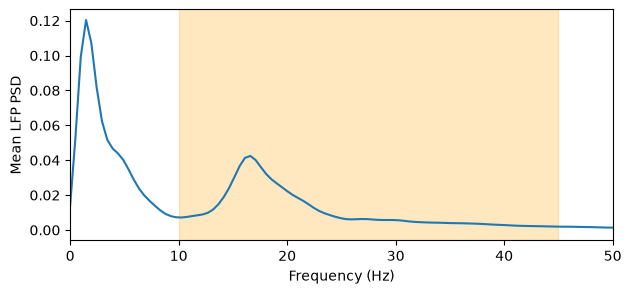

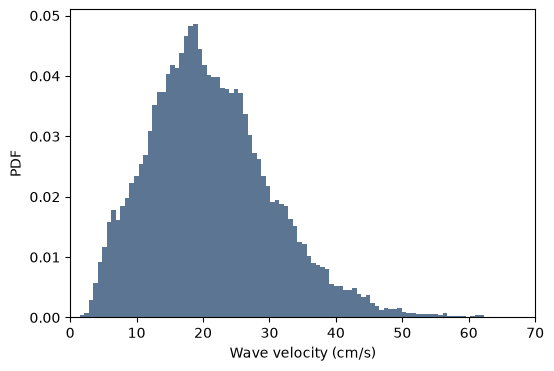

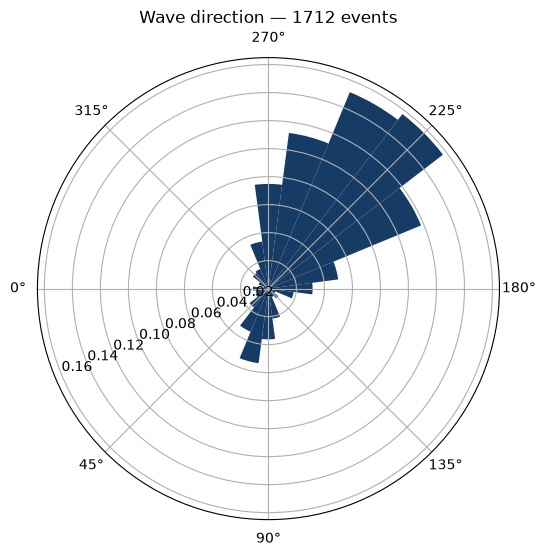

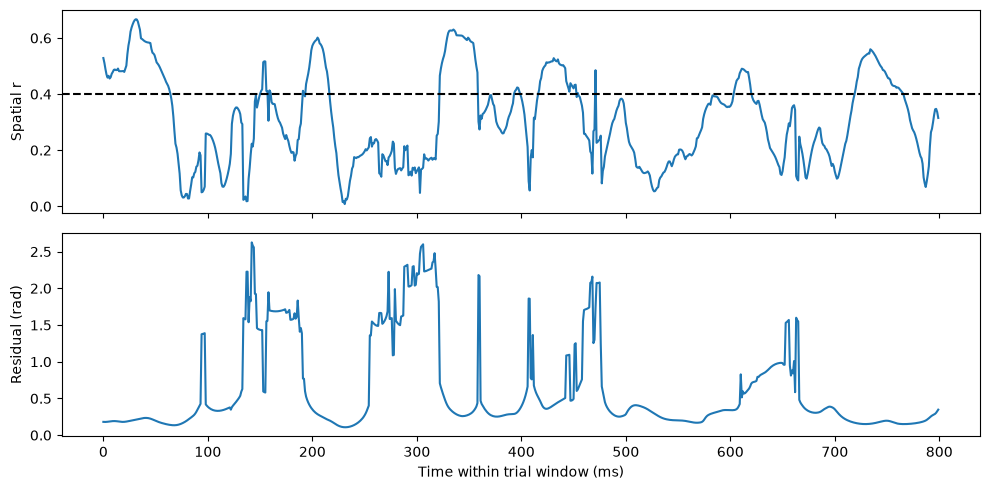

In [7]:

fig,ax = plt.subplots(figsize=(7,3))
ax.plot(frequencies,mean_psd)
ax.axvspan(*band_hz,color="orange",alpha=.25)
ax.set(xlim=(0,50),xlabel="Frequency (Hz)",ylabel="Mean LFP PSD")
plt.show()

speeds = speed_results["all_speeds"]
if len(speeds):
    fig,ax = plt.subplots(figsize=(6,4))
    ax.hist(speeds,bins=100,density=True,color="#163B65",alpha=.7)
    ax.set(xlim=(0,70),xlabel="Wave velocity (cm/s)",ylabel="PDF")
    plt.show()
angles = Macaque_final["wave_directions"]
angles = angles[np.isfinite(angles)]
if len(angles):
    width = 2*np.pi/N_DIRECTION_BINS
    edges = np.arange(N_DIRECTION_BINS+1)*width-width/2
    wrapped = (angles+width/2)%(2*np.pi)-width/2
    counts,_ = np.histogram(wrapped,bins=edges)
    fig,ax = plt.subplots(figsize=(6,6),subplot_kw={"projection":"polar"})
    ax.bar(edges[:-1]+width/2,counts/len(angles),width=1*width,color="#163B65")
    ax.set_theta_zero_location("E"); ax.set_theta_direction(1)
    ax.set_theta_offset(np.pi) #this is to align the caudal direction at the top of the plot - as in Fig 5
    ax.set_title(f"Wave direction — {len(angles)} events")

    ax.set_title(f"Wave direction — {len(angles)} events")

    fig.savefig("wave_directions.svg", format="svg",
                bbox_inches="tight", transparent=True)

    plt.show()

 
if trial_results:
    first = trial_results[0]
    t = np.arange(len(first["R"]))*LFP_SAMPLE_INTERVAL_MS
    fig,axes = plt.subplots(2,1,figsize=(10,5),sharex=True)
    axes[0].plot(t,first["R"]); axes[0].axhline(FIXED_R_THRESHOLD,color="k",ls="--")
    axes[0].set_ylabel("Spatial r")
    axes[1].plot(t,first["e_resid"])
    axes[1].set(xlabel="Time within trial window (ms)",ylabel="Residual (rad)")
    fig.tight_layout(); plt.show()


## Saved results

The output MAT file contains two variables:

- `Macaque_final`: frame-wise speeds from accepted events (`all_speeds`, in cm/s), event-mean speeds (`event_mean_speeds`), propagation directions, wavelengths, event records, and analysis settings.
- `Macaque_data`: per-trial measurements, including spatial coherence (`R`), phase-plane residuals (`e_resid`), speeds, fitted phase gradients, and accepted-frame masks.

The speed distributions differ in how observations are weighted: `all_speeds` contains a value for each accepted frame with a finite speed estimate, whereas `event_mean_speeds` contributes one value per detected event. Spatial coherence is a detection criterion, not a statistical significance test. Changing the coherence threshold can shorten or split events and thereby affect estimated wave properties.


In [8]:
total = pass_r = accepted = 0
longest_run = 0

for trial in trial_results:
    r = trial["R"]

    good_r = r > FIXED_R_THRESHOLD

    total += len(r)
    pass_r += good_r.sum()
    accepted += trial["accepted"].sum()

    changes = np.flatnonzero(
        np.diff(np.r_[False, good_r, False].astype(int))
    )
    lengths = changes[1::2] - changes[::2]
    if lengths.size:
        longest_run = max(longest_run, lengths.max())

print(f"Pass r threshold:    {100 * pass_r / total:.2f}%")
print(f"In accepted events:  {100 * accepted / total:.2f}%")
print(f"Longest r run:       {longest_run * LFP_SAMPLE_INTERVAL_MS:g} ms")

all_r = np.concatenate([t["R"] for t in trial_results])
all_res = np.concatenate([t["e_resid"] for t in trial_results])
print("Percentiles:        10, 25, 50, 75, 90")
print("Spatial r:         ", np.nanpercentile(all_r, [10, 25, 50, 75, 90]))
print("Residual (rad):    ", np.nanpercentile(all_res, [10, 25, 50, 75, 90]))
print("Filter band (Hz):  ", band_hz)


Pass r threshold:    20.40%
In accepted events:  18.02%
Longest r run:       133 ms
Percentiles:        10, 25, 50, 75, 90
Spatial r:          [0.1093055  0.17872298 0.27224713 0.37601911 0.4723176 ]
Residual (rad):     [0.17018074 0.22602934 0.3413972  0.66471981 1.529505  ]
Filter band (Hz):   (10.0, 45.0)
